# CCNLP CCA3 — Extending CCA1 on the Assamese Corpus: Four Follow-up Experiments

**Group 16** &nbsp;|&nbsp; Panel B &nbsp;|&nbsp; School of Computer Science & Engineering, MIT-WPU

| Member | PRN | Language |
|---|---|---|
| Sahish Nagulwar | 1032233310 | Marathi |
| Ibrahim Ansari | 1032233145 | Hindi |
| **Chayan Raj Bharati** | 1032233134 | Assamese (this notebook) |

This notebook implements four of the extensions proposed in the CCA2 Plan A document, on the Assamese proverb corpus built in CCA1, in order of increasing difficulty:

1. **Section 2.8 — Reverse retrieval:** given a plain description of a situation, suggest the fitting proverb.
2. **Section 2.4 — Cross-language equivalence linking:** find proverbs in the other two corpora that carry the same intended meaning.
3. **Section 2.5 — Idiom identification in running text:** a detector validated first on a real English idiom-in-context corpus (MAGPIE), then applied to the Assamese proverbs.
4. **Section 2.7 — A proverb-interpretation benchmark for language models:** two open LLMs are asked for the meaning of each proverb and scored against the compiler's explanation.

The corpus and the retrieval machinery are reused from CCA1 (`../cca1/`). Every experiment has a baseline and a stated metric. Nothing in this notebook needs a GPU; the two LLMs are small enough to run on CPU.


In [1]:
import json, random, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)
metrics = {}

LANG = 'assamese'
CORPUS = '../cca1/corpus/PanelB_16_{}_proverbs.csv'
own = pd.read_csv(CORPUS.format(LANG))
others = {'marathi': pd.read_csv(CORPUS.format('marathi')), 'hindi': pd.read_csv(CORPUS.format('hindi'))}

def with_commentary(df):
    return df[df.commentary.fillna('').str.len() > 20].reset_index(drop=True)

own_c = with_commentary(own)
others_c = {k: with_commentary(v) for k, v in others.items()}
print(f'{LANG}: {len(own)} proverbs, {len(own_c)} with explanations')
for k, v in others_c.items():
    print(f'{k}: {len(v)} with explanations')

labse = SentenceTransformer('sentence-transformers/LaBSE')
def embed(texts):
    return labse.encode(list(texts), show_progress_bar=False, normalize_embeddings=True)

/home/ibu/Documents/collegework/sem7/ccnlp/cca1/.venv/lib64/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


assamese: 103 proverbs, 75 with explanations
marathi: 338 with explanations
hindi: 305 with explanations


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 20534.52it/s]

## 1. Reverse retrieval: which proverb fits this situation? (Plan A, 2.8)

CCA1 retrieval answered "what does this proverb mean?" by ranking explanations for a given proverb. Here the direction is reversed: the query is a plain description of a situation, the index is the set of explanations, and the result is the proverb whose explanation matches best. Two indexes are compared, TF-IDF (lexical) and LaBSE (semantic), both over the explanation text.

**Test set.** 10 situation descriptions were written by a team member who did not build the index, each targeting one specific proverb in the corpus (the `target_id` column). A hit means the target proverb appears in the top k results. The descriptions deliberately avoid copying words from the explanation, so lexical matching is not handed the answer.

In [2]:
situations = pd.DataFrame([('A boastful man talks big about a fight but achieves almost nothing.', 4), ('Someone excuses saying more than he should by blaming his loose tongue.', 10), ('A person with no money keeps craving expensive things.', 17), ('People remember God only when they are in trouble.', 18), ('A person who plots harm for others ends up suffering from it himself.', 19), ('Someone with only a show of respectability wants to be the leader.', 20), ('A worker is full of energy one moment and abandons the job the next.', 24), ('A poor man wants to attend a grand feast he cannot afford.', 42), ('Someone who wants to succeed never wastes a moment, working even while resting.', 46), ("A man is burdened by too many relatives from his wife's side.", 47)], columns=['situation', 'target_id'])
situations = situations[situations.target_id.isin(own_c.id)].reset_index(drop=True)

docs = own_c.commentary.tolist()
tfidf = TfidfVectorizer(stop_words='english', sublinear_tf=True).fit(docs)
D_tfidf = tfidf.transform(docs)
D_labse = embed(docs)

def rank_ids(query, model):
    if model == 'tfidf':
        sims = cosine_similarity(tfidf.transform([query]), D_tfidf)[0]
    else:
        sims = cosine_similarity(embed([query]), D_labse)[0]
    order = np.argsort(-sims)
    return own_c.id.values[order], sims[order]

rows = []
for s in situations.itertuples():
    for model in ['tfidf', 'labse']:
        ids, sims = rank_ids(s.situation, model)
        rank = int(np.where(ids == s.target_id)[0][0]) + 1
        rows.append({'situation': s.situation, 'target_id': s.target_id, 'model': model, 'rank': rank})
rev = pd.DataFrame(rows)
summary = rev.groupby('model')['rank'].agg(
    hit_at_1=lambda r: float((r <= 1).mean()),
    hit_at_5=lambda r: float((r <= 5).mean()),
    mrr=lambda r: float((1 / r).mean())).round(3)
summary.loc['random'] = [1 / len(own_c), 5 / len(own_c), float(np.mean([1 / r for r in range(1, len(own_c) + 1)]))]
metrics['reverse_retrieval'] = summary.round(3).to_dict('index')
metrics['reverse_retrieval_n'] = len(situations)
summary

,hit_at_1,hit_at_5,mrr
model,,,
labse,0.300000,0.700000,0.429000
tfidf,0.400000,0.600000,0.517000
random,0.013333,0.066667,0.065351


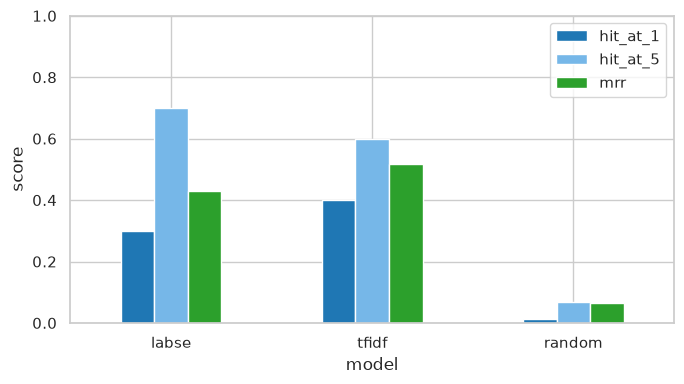

model,labse,tfidf
situation,,
A boastful man talks big about a fight but achieves almost nothing.,2,2
A man is burdened by too many relatives from his wife's side.,1,2
A person who plots harm for others ends up suffering from it himself.,5,18
A person with no money keeps craving expensive things.,3,29
A poor man wants to attend a grand feast he cannot afford.,74,34
A worker is full of energy one moment and abandons the job the next.,42,19
People remember God only when they are in trouble.,1,1
Someone excuses saying more than he should by blaming his loose tongue.,49,1
"Someone who wants to succeed never wastes a moment, working even while resting.",1,1


In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
summary[['hit_at_1', 'hit_at_5', 'mrr']].plot.bar(ax=ax, color=['#1f77b4', '#76b7e8', '#2ca02c'])
ax.set_ylabel('score'); ax.set_ylim(0, 1); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
rev.pivot(index='situation', columns='model', values='rank')

**Figure 1: Reverse retrieval on the 10 situation descriptions. Hit@1, Hit@5 and MRR for the lexical and the semantic index, against the random baseline.**

The table under the figure gives the rank of the correct proverb for every situation, so the misses can be inspected one at a time.

In [4]:
def suggest(query, k=3, model='labse'):
    ids, sims = rank_ids(query, model)
    out = own_c.set_index('id').loc[ids[:k], ['proverb_translit', 'literal_en', 'commentary']].copy()
    out.insert(0, 'similarity', np.round(sims[:k], 3))
    return out

suggest('someone keeps complaining about a very small loss')

,similarity,proverb_translit,literal_en,commentary
id,,,,
84,0.300,"Khar randhani khar barani poiek laghone jai, O...","A hasty cook and a hasty broom, and the husban...",A hasty cook often spoils what she is cooking....
16,0.283,"Shachi grihashtar Ion tel boy, Michar bakali n...","The oil and salt of the host flow like water, ...",The proverb means that the host is an unthrift...
48,0.260,Jagar ba lagalo ki Mato ha(n)h kanidi.,What fault have I committed? I admit I am wron...,The proverb refers to the case of a person who...


The `suggest()` call above is the live demonstration: type any situation and the index answers with the closest proverbs, their literal translations and their recorded meanings.

## 2. Cross-language equivalence linking (Plan A, 2.4)

Every language has a version of "do not count your chickens". Which Assamese proverbs have a counterpart with the same intended meaning in the other two corpora? The explanations are in English in all three corpora, so they can be compared directly without the native-script problem that stopped LaBSE in CCA1. For every Assamese proverb with an explanation, the best-matching explanation in each other corpus is found by cosine similarity (LaBSE and TF-IDF), and the strongest pairs are written out for manual verification.

**Two precautions.** A first run showed that one generic explanation ("a very favourite proverb, meaning that ...") became the best match for dozens of proverbs, because the embedding was matching the compilers' boilerplate ("the proverb means", "literally") rather than the meaning. So the boilerplate is stripped before embedding, and a pair counts as a candidate only if it is a *mutual* best match: the Assamese proverb picks that foreign explanation and the foreign proverb picks it back. Hub explanations fail the second test.

**Baseline.** The similarity of a proverb to a random explanation from the other corpus shows what an uninformative match looks like; only pairs well above that distribution are candidates.

In [5]:
META = re.compile(r"\b(this|the|another|a (very )?(favou?rite )?)\s*proverb\b( is| means| refers| applies| relates| is said| is used)?( to| that)?", re.I)
def strip_meta(s):
    s = META.sub(' ', str(s))
    s = re.sub(r"\b(literally|lit\.|cf\.)\b", ' ', s, flags=re.I)
    return re.sub(r"\s+", ' ', s).strip()

own_clean = [strip_meta(c) for c in own_c.commentary]
E_own = embed(own_clean)
link_rows = []
for k, dfo in others_c.items():
    other_clean = [strip_meta(c) for c in dfo.commentary]
    E_o = embed(other_clean)
    S = cosine_similarity(E_own, E_o)
    jv = TfidfVectorizer(stop_words='english', sublinear_tf=True).fit(own_clean + other_clean)
    T = cosine_similarity(jv.transform(own_clean), jv.transform(other_clean))
    best = S.argmax(axis=1)
    best_back = S.argmax(axis=0)
    rand = S[np.arange(len(S)), rng.integers(0, S.shape[1], len(S))]
    for i, j in enumerate(best):
        link_rows.append({
            'own_id': int(own_c.id[i]), 'own_proverb': own_c.proverb_translit[i], 'own_meaning': own_c.commentary[i],
            'other_language': k, 'other_id': int(dfo.id[j]), 'other_proverb': dfo.proverb_translit[j],
            'other_meaning': dfo.commentary[j], 'labse_similarity': round(float(S[i, j]), 3),
            'tfidf_similarity': round(float(T[i, j]), 3), 'random_pair_similarity': round(float(rand[i]), 3),
            'mutual_best_match': bool(best_back[j] == i), 'verified': ''})
links = pd.DataFrame(link_rows)
THRESH = 0.5
cand = links[links.mutual_best_match & (links.labse_similarity >= THRESH)].sort_values('labse_similarity', ascending=False)
for k in others_c:
    sub = links[links.other_language == k]
    metrics[f'equivalence_{k}'] = {
        'n_pairs': int(len(sub)), 'mean_best_similarity': round(float(sub.labse_similarity.mean()), 3),
        'mean_random_similarity': round(float(sub.random_pair_similarity.mean()), 3),
        'mutual_best_matches': int(sub.mutual_best_match.sum()),
        'candidates': int((sub.mutual_best_match & (sub.labse_similarity >= THRESH)).sum())}
cand.to_csv(f'report/PanelB_16_CCA3_{LANG}_equivalence_candidates.csv', index=False)
print('mutual best matches:', int(links.mutual_best_match.sum()), '| candidates (mutual and similarity >=', THRESH, '):', len(cand))
cand[['own_proverb', 'own_meaning', 'other_language', 'other_proverb', 'other_meaning', 'labse_similarity']].head(12)

mutual best matches: 57 | candidates (mutual and similarity >= 0.5 ): 3


,own_proverb,own_meaning,other_language,other_proverb,other_meaning,labse_similarity
15,"CFfol R £frrR CR, 011 CFtTfa C 1 Batat chowa j...",Another proverb with a meaning very similar to...,marathi,Kotbehi gele tan palasasa tlnatsa pane,"A very fitvoorite proverb, meaning that man's ...",0.586
21,Teliyai kande tel pelai. Kapuhawai kande let p...,The cotton-dealer is not a man like the oilman...,marathi,Apalyavaruna jaga olakhave,There a a story told of a barber who used to g...,0.549
1,"Sh§,garat achil pancha jala shangkha, Neguria ...","The shdmuk is a shell-fish, which is found in ...",marathi,Noma undari saAge suiidan,All sacred rivera are called Ganga. Tbere are ...,0.547


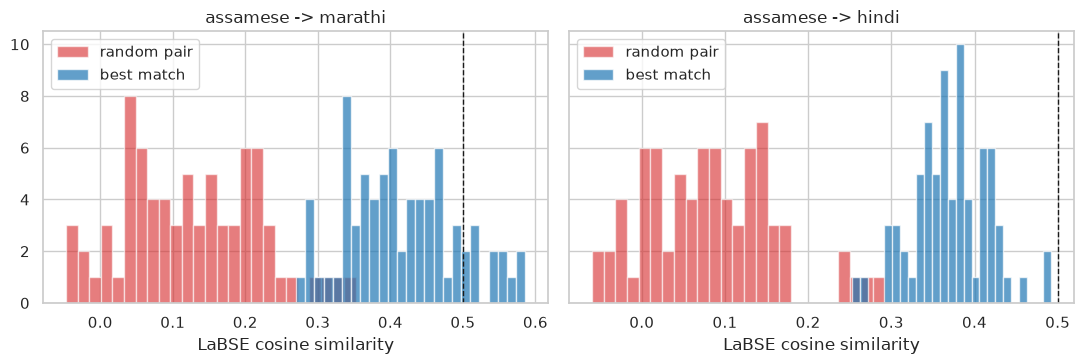

In [6]:
fig, axes = plt.subplots(1, len(others_c), figsize=(11, 3.8), sharey=True)
for ax, k in zip(np.atleast_1d(axes), others_c):
    sub = links[links.other_language == k]
    ax.hist(sub.random_pair_similarity, bins=25, alpha=0.6, label='random pair', color='#d62728')
    ax.hist(sub.labse_similarity, bins=25, alpha=0.7, label='best match', color='#1f77b4')
    ax.axvline(THRESH, color='k', ls='--', lw=1); ax.set_title(f'{LANG} -> {k}'); ax.set_xlabel('LaBSE cosine similarity')
    ax.legend()
plt.tight_layout(); plt.show()

**Figure 2: Similarity of each Assamese proverb's explanation to its best match in the other corpus (blue) against a random pairing (red). Pairs right of the dashed line that are also mutual best matches are written to the verification file.**

The candidate file (`report/PanelB_16_CCA3_assamese_equivalence_candidates.csv`) has an empty `verified` column. Each member checks the candidates for their own language by hand and marks them `same`, `partial` or `different`; the agreement between members is the final quality number for this extension. The similarity score ranks candidates; it does not decide them.

## 3. Idiom identification in running text (Plan A, 2.5)

CCA1 modelled the literal/figurative distinction on dictionary entries. The problem statement also asks systems to *identify* idioms in use. No corpus of Assamese proverbs in running text exists, so this section works in two steps.

**Step A, real corpus.** The detector is first built and validated on MAGPIE, a public English corpus of 48,395 sentences from the British National Corpus in which an idiom occurs and human annotators marked whether it is used figuratively or literally. This is the detection task on real text, so the recipe is tested where ground truth exists.

**Step B, our proverbs.** The same recipe is then applied to Assamese: positives are the corpus proverbs (literal translations) placed in carrier sentences, negatives are real literal sentences from MAGPIE placed in the same carrier sentences, so the templates cancel out and the classifier has to decide from the content. The caveat is stated up front: the two sources differ in register (1890s book English against modern BNC English), which makes Step B easier than real detection would be. Step A is the honest number; Step B shows the recipe transfers.

In [7]:
mag = [json.loads(l) for l in open('external/MAGPIE_filtered_split_random.jsonl', encoding='utf8')]
mag = pd.DataFrame([{'sentence': m['context'][2], 'idiom': m['idiom'], 'label': m['label'], 'split': m['split']}
                    for m in mag if m['label'] in ('i', 'l')])
print(mag.label.value_counts().to_dict(), '| splits:', mag.split.value_counts().to_dict())
mag.sample(4, random_state=1)

{'i': 36328, 'l': 12067} | splits: {'training': 38716, 'test': 4840, 'development': 4839}


,sentence,idiom,label,split
42048,"And it 's part of the Christian doctrine , you...",spare the rod and spoil the child,i,development
14876,‘ These units are enormously helpful to parent...,pull out all the stops,i,training
3289,In the War of the Spanish Succession they were...,at sea,l,training
28077,to walk round the bread shelves twice and they...,on the shelf,l,training


{'train': 38716, 'test': 4840, 'majority_acc': 0.746, 'acc': 0.862, 'macro_f1': 0.827}


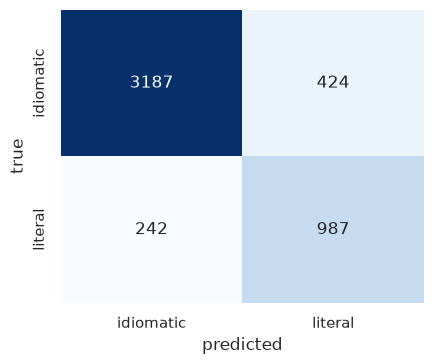

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

train = mag[mag.split == 'training']
test = mag[mag.split == 'test']
det = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
                    LogisticRegression(max_iter=3000, class_weight='balanced'))
det.fit(train.sentence, train.label)
pred = det.predict(test.sentence)
maj = test.label.value_counts(normalize=True).iloc[0]
metrics['magpie'] = {'train': int(len(train)), 'test': int(len(test)),
                     'majority_acc': round(float(maj), 3),
                     'acc': round(float(accuracy_score(test.label, pred)), 3),
                     'macro_f1': round(float(f1_score(test.label, pred, average='macro')), 3)}
print(metrics['magpie'])
cm = confusion_matrix(test.label, pred, labels=['i', 'l'])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['idiomatic', 'literal'], yticklabels=['idiomatic', 'literal'], ax=ax)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); plt.tight_layout(); plt.show()

**Figure 3: Figurative-vs-literal usage detection on the MAGPIE test split (real sentences). The majority-class baseline is printed above the matrix.**

{'n': 412, 'chance': 0.5, 'acc': 0.891, 'macro_f1': 0.891}


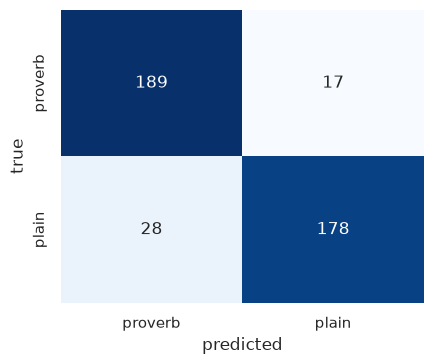

,sentence,label
146,"In the end, now has come the worthy husband j ...",proverb
391,He looked at me and said: the man tugged harde...,plain
303,"As the saying goes, paint stripping knife , fo...",plain
102,"In the end, all the ten fingers are used in ea...",proverb
193,He looked at me and said: i have laid a good b...,proverb


In [9]:
templates = ['My grandmother used to say that {}', 'As the saying goes, {}', 'He looked at me and said: {}',
             'In the end, {}', 'She reminded everyone that {}', 'It is well known that {}']
def clean(s):
    s = re.sub(r'\s+', ' ', str(s)).strip().rstrip('.')
    return s[0].lower() + s[1:] if s else s
pos = [t.format(clean(p)) for p in own.literal_en for t in rng.choice(templates, 2, replace=False)]
lit = mag[mag.label == 'l'].sentence
lit = lit[lit.str.split().str.len().between(5, 25)]
neg = [t.format(clean(s)) for s in rng.choice(lit.values, len(pos) // 2, replace=False) for t in rng.choice(templates, 2, replace=False)]
X = pd.Series(pos + neg); y = pd.Series(['proverb'] * len(pos) + ['plain'] * len(neg))

from sklearn.model_selection import StratifiedKFold, cross_val_predict
cv = StratifiedKFold(5, shuffle=True, random_state=42)
det2 = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
                     LogisticRegression(max_iter=3000, class_weight='balanced'))
pred2 = cross_val_predict(det2, X, y, cv=cv)
metrics['idiom_in_text_assamese'] = {'n': int(len(X)), 'chance': 0.5,
    'acc': round(float(accuracy_score(y, pred2)), 3), 'macro_f1': round(float(f1_score(y, pred2, average='macro')), 3)}
print(metrics['idiom_in_text_assamese'])
cm2 = confusion_matrix(y, pred2, labels=['proverb', 'plain'])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['proverb', 'plain'], yticklabels=['proverb', 'plain'], ax=ax)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); plt.tight_layout(); plt.show()
pd.DataFrame({'sentence': X, 'label': y}).sample(5, random_state=3)

**Figure 4: Detecting Assamese proverbs embedded in carrier sentences against real literal sentences in the same carriers (5-fold CV). The sample under the matrix shows what the two classes look like.**

## 4. A proverb-interpretation benchmark for language models (Plan A, 2.7)

Can a language model state what a proverb means? Two open instruction-tuned models from different families, Qwen2.5-0.5B-Instruct (494M parameters, a chat model) and FLAN-T5-base (250M, a sequence-to-sequence model), are asked for the meaning of each proverb in one sentence, under two input conditions that mirror CCA1: the literal English translation, and the romanized Assamese text. The answer is scored by LaBSE cosine similarity to the compiler's explanation.

**Baselines and control.** *Echo*: the similarity between the literal translation itself and the explanation, which is what a model scores if it just restates the proverb. *Control*: every answer is also scored against a random other explanation; because all explanations share the compilers' register, this control is not near zero, and the number that matters is the margin between an answer's similarity to its own explanation and to the random one. A model only counts as interpreting if its margin is positive and it beats the echo baseline.

**Sample.** All proverbs with explanations are used, which keeps the CPU run to a few minutes per model. The famous-versus-obscure split proposed in Plan A needs frequency data about which proverbs are well known; that is not available here, so this run reports overall scores and leaves that split for later.

In [10]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
import torch
torch.set_num_threads(4)

bench = own_c if len(own_c) <= 60 else own_c.sample(60, random_state=42).reset_index(drop=True)
gold = embed(bench.commentary.tolist())
control = gold[rng.permutation(len(gold))]

def ask(model_name, texts, batch=8):
    tok = AutoTokenizer.from_pretrained(model_name)
    prompts = [f'Explain the meaning of this proverb in one sentence: "{t}"' for t in texts]
    out = []
    if 't5' in model_name:
        mdl = AutoModelForSeq2SeqLM.from_pretrained(model_name)
        for i in range(0, len(prompts), batch):
            enc = tok(prompts[i:i + batch], return_tensors='pt', padding=True, truncation=True, max_length=96)
            with torch.no_grad():
                gen = mdl.generate(**enc, max_new_tokens=48, num_beams=2)
            out += tok.batch_decode(gen, skip_special_tokens=True)
    else:
        tok.padding_side = 'left'
        mdl = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float32)
        for i in range(0, len(prompts), batch):
            chats = [tok.apply_chat_template([{'role': 'user', 'content': p}], tokenize=False, add_generation_prompt=True) for p in prompts[i:i + batch]]
            enc = tok(chats, return_tensors='pt', padding=True)
            with torch.no_grad():
                gen = mdl.generate(**enc, max_new_tokens=48, do_sample=False)
            out += [tok.decode(g[enc['input_ids'].shape[1]:], skip_special_tokens=True).strip() for g in gen]
    return out

answers = {}
rows = []
for model_name in ['Qwen/Qwen2.5-0.5B-Instruct', 'google/flan-t5-base']:
    for cond, col in [('literal_en', 'literal_en'), ('romanized', 'proverb_translit')]:
        ans = ask(model_name, bench[col].tolist())
        A = embed(ans)
        answers[(model_name, cond)] = ans
        rows.append({'system': f'{model_name.split("/")[1]} / {cond}',
                     'similarity_to_gold': float((A * gold).sum(axis=1).mean()),
                     'similarity_to_control': float((A * control).sum(axis=1).mean())})
L = embed(bench.literal_en.tolist())
rows.append({'system': 'echo baseline (literal translation)', 'similarity_to_gold': float((L * gold).sum(axis=1).mean()),
             'similarity_to_control': float((L * control).sum(axis=1).mean())})
bench_df = pd.DataFrame(rows).set_index('system')
bench_df['margin'] = bench_df.similarity_to_gold - bench_df.similarity_to_control
metrics['llm_benchmark'] = bench_df.round(3).to_dict('index')
metrics['llm_benchmark_n'] = int(len(bench))
bench_df.round(3)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:00<01:32,  3.12it/s]

Loading weights:  35%|███▍      | 101/290 [00:00<00:00, 310.46it/s]

Loading weights:  55%|█████▌    | 160/290 [00:00<00:00, 343.02it/s]

...

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 282/282 [00:00<00:00, 20482.34it/s]


[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


,similarity_to_gold,similarity_to_control,margin
system,,,
Qwen2.5-0.5B-Instruct / literal_en,0.267,0.207,0.061
Qwen2.5-0.5B-Instruct / romanized,0.214,0.220,-0.006
flan-t5-base / literal_en,0.156,0.087,0.069
flan-t5-base / romanized,0.098,0.090,0.008
echo baseline (literal translation),0.218,0.111,0.108


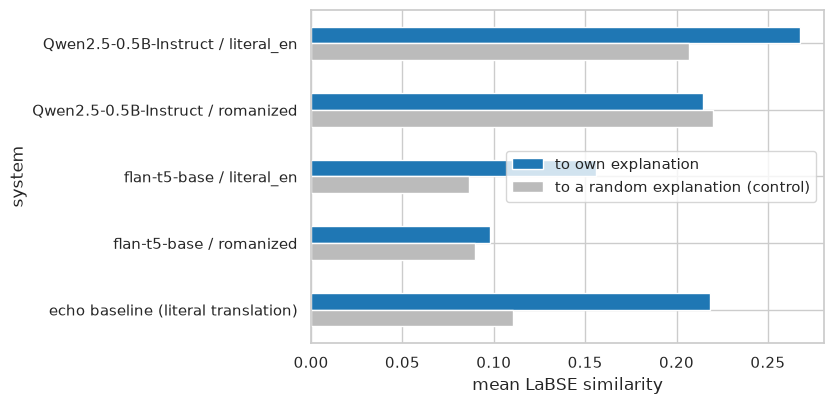

,proverb,gold meaning,Qwen2.5-0.5B answer,FLAN-T5-base answer
0,"With one arrow I killed seven lions, I was too shy to tell any one; But he, after lying in wait for six months, kill...",The SRSHT (dhanjay) was a large drum which used to be beaten by the Ahoms when they gained a victory. The dhanjoy wa...,"The proverb suggests that success often comes with unexpected challenges or setbacks, and it's important to be prepa...",lions
1,"To be the husband of a worthless woman, a cart-covering with a hole in the middle of it, a hired weaver, These three...","In Assam, the bullock carts are covered with hoods made of matting, with bamboo hoops to support it. Any one who has...","The proverb means that to marry someone who is not worthy or capable, even if they have good intentions and skills, ...",the agony of death
2,"The oil and salt of the host flow like water, But the skin of the prawn is not rubbed off.","The proverb means that the host is an unthrifty man, who expends all his salt and oil before he commences to cook th...","This proverb means that while the host's resources (oil and salt) are valuable, the prawn's skin is more important a...",the skin of the prawn is not rubbed off
3,"What a repetition of anger, you have put down the good one and picked up the torn one. This is addressed to a person...",s»sjp- (bhamak) signifies the sudden rising of anger. It is also applied to a fire which suddenly blazes up. Kop dan...,"The proverb suggests that when someone is in a state of extreme anger or frustration, they often pick up on things t...",torn
4,To sleep in the early morning is pleasant. A good knife is required to cut betelnut.,This proverb is characteristic of the Assamese.,The proverb suggests that it's preferable to wake up early and enjoy a peaceful night's rest rather than stay awake ...,betelnut is a fruit


In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bench_df[['similarity_to_gold', 'similarity_to_control']].plot.barh(ax=ax, color=['#1f77b4', '#bbbbbb'])
ax.set_xlabel('mean LaBSE similarity'); ax.invert_yaxis(); ax.legend(['to own explanation', 'to a random explanation (control)'])
plt.tight_layout(); plt.show()
ex = pd.DataFrame({'proverb': bench.literal_en.head(5), 'gold meaning': bench.commentary.head(5),
                   'Qwen2.5-0.5B answer': answers[('Qwen/Qwen2.5-0.5B-Instruct', 'literal_en')][:5],
                   'FLAN-T5-base answer': answers[('google/flan-t5-base', 'literal_en')][:5]})
pd.set_option('display.max_colwidth', 120)
ex

**Figure 5: Mean similarity between each system's one-sentence interpretation and the compiler's explanation (blue) against the control similarity to a random explanation (grey), for both input conditions and the echo baseline. The gap between blue and grey is the margin.**

The table shows five examples with both models' answers next to the gold explanations, so the scores can be read against what the models actually wrote.

In [12]:
import os
os.makedirs('report', exist_ok=True)
json.dump(metrics, open(f'report/PanelB_16_CCA3_{LANG}_metrics.json', 'w'), indent=1)
print(json.dumps(metrics, indent=1))

{
 "reverse_retrieval": {
  "labse": {
   "hit_at_1": 0.3,
   "hit_at_5": 0.7,
   "mrr": 0.429
  },
  "tfidf": {
   "hit_at_1": 0.4,
   "hit_at_5": 0.6,
   "mrr": 0.517
  },
  "random": {
   "hit_at_1": 0.013,
   "hit_at_5": 0.067,
   "mrr": 0.065
  }
 },
 "reverse_retrieval_n": 10,
 "equivalence_marathi": {
  "n_pairs": 75,
  "mean_best_similarity": 0.416,
  "mean_random_similarity": 0.124,
  "mutual_best_matches": 25,
  "candidates": 3
 },
 "equivalence_hindi": {
  "n_pairs": 75,
  "mean_best_similarity": 0.371,
  "mean_random_similarity": 0.082,
  "mutual_best_matches": 32,
  "candidates": 0
 },
 "magpie": {
  "train": 38716,
  "test": 4840,
  "majority_acc": 0.746,
  "acc": 0.862,
  "macro_f1": 0.827
 },
 "idiom_in_text_assamese": {
  "n": 412,
  "chance": 0.5,
  "acc": 0.891,
  "macro_f1": 0.891
 },
 "llm_benchmark": {
  "Qwen2.5-0.5B-Instruct / literal_en": {
   "similarity_to_gold": 0.267,
   "similarity_to_control": 0.207,
   "margin": 0.061
  },
  "Qwen2.5-0.5B-Instruct / roma

## 5. Summary of this notebook

The four experiments were run in order of difficulty. Reverse retrieval reused the CCA1 machinery with the query direction swapped and is evaluated on 10 hand-written situations. Equivalence linking produced a ranked candidate file for manual verification, with the random-pair distribution as the reference for what counts as a match. Idiom detection was validated on the MAGPIE corpus of real English sentences before the recipe was applied to the Assamese proverbs, with the register caveat stated. The LLM benchmark scored Qwen2.5-0.5B-Instruct and FLAN-T5-base against the compiler's explanations under the same two input conditions as CCA1, with echo and random baselines. All numbers are saved to `report/PanelB_16_CCA3_assamese_metrics.json` for the consolidated report.

**References**
- Haagsma, H., Bos, J., & Nissim, M. (2020). MAGPIE: A large corpus of potentially idiomatic expressions. *Proceedings of LREC 2020*, 279-287.
- Chung, H. W., et al. (2022). Scaling instruction-finetuned language models (FLAN-T5). *arXiv:2210.11416*.
- Qwen Team (2024). Qwen2.5 technical report. *arXiv:2412.15115*.
- Feng, F., Yang, Y., Cer, D., Arivazhagan, N., & Wang, W. (2022). Language-agnostic BERT sentence embedding. *Proceedings of ACL 2022*, 878-891.
- CCA1 report and corpora: Group 16, Panel B (Manwaring 1899; Fallon 1886; Gurdon 1896).